## Ejemplo de la máquina de chicles

El éxito es que salgan chicles rojos en una extracción con reposición de n = 10.

Primeras 1 muestras: 7


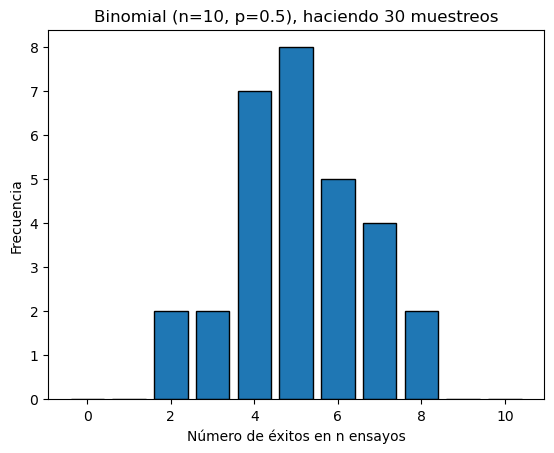

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros de la distribución
n = 10      # número de ensayos
p = 0.5     # probabilidad de éxito en cada ensayo
muestras = 30  # cantidad de muestras
datos = np.random.binomial(n, p, muestras)# Generar las muestras

# Mostrar algunas muestras
print("Primeras 1 muestras:", datos[12])

# Graficar histograma
plt.hist(datos, bins=range(n+2), align='left', rwidth=0.8, edgecolor='black')
plt.xlabel('Número de éxitos en n ensayos')
plt.ylabel('Frecuencia')
plt.title(f'Binomial (n={n}, p={p}), haciendo {muestras} muestreos')
plt.show()

## Test de hipótesis binomial

Aquí encontramos un modelo matemático para representar el test.

In [2]:
from scipy.stats import binom
n = 10      # número de ensayos
p = 0.5     # probabilidad de éxito
alfa = 0.05    # cuantil deseado
x_alfa_2 = binom.ppf(alfa/2, n, p)
x_1_alfa_2 = binom.ppf(1-alfa/2, n, p)
alpha = "α"
print(f"x({alpha}/2):",x_alfa_2)
print(f"x(1-{alpha}/2):",x_1_alfa_2)

x(α/2): 2.0
x(1-α/2): 8.0


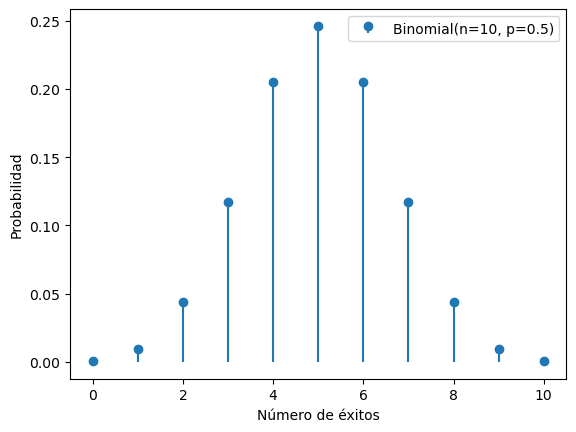

In [3]:
plt.figure(2)
x = np.arange(0, 11)
y_binom = binom.pmf(x, n=10, p=0.5)
y_binom2 = binom.pmf(x, n=10, p=0.9)
plt.stem(x, y_binom, linefmt="C0-", markerfmt="C0o", basefmt=" ", label=f"Binomial(n={n}, p={0.5})")
# plt.stem(x, y_binom2, linefmt="C1-", markerfmt="C1s", basefmt=" ", label=f"Binomial(n={n}, p={0.9})")
plt.xlabel("Número de éxitos")
plt.ylabel("Probabilidad")
# plt.title("Distribuciones Binomiales con diferente p")
plt.legend()
plt.show()


## Error de tipo II:



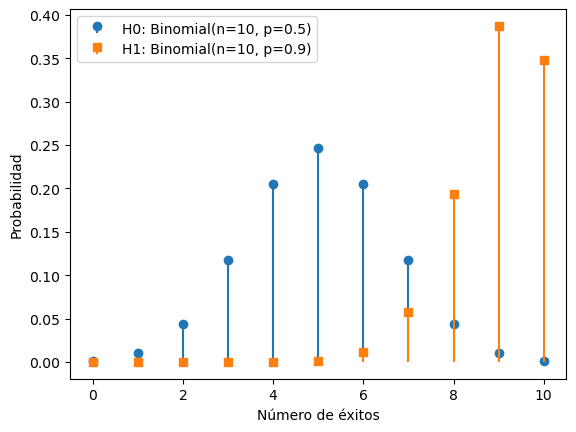

In [4]:
x = np.arange(0, 11)
plt.figure(3)
y_binom = binom.pmf(x, n=10, p=0.5)
y_binom2 = binom.pmf(x, n=10, p=0.9)
plt.stem(x, y_binom, linefmt="C0-", markerfmt="C0o", basefmt=" ", label=f"H0: Binomial(n={n}, p={0.5})")
plt.stem(x, y_binom2, linefmt="C1-", markerfmt="C1s", basefmt=" ", label=f"H1: Binomial(n={n}, p={0.9})")
plt.xlabel("Número de éxitos")
plt.ylabel("Probabilidad")
plt.legend()
plt.show()

In [5]:
p1 = 0.9
beta = binom.cdf(8, n, p1)-binom.cdf(1, n, p1)# P(2<= x <= 8)
print('Error de tipo II, β: ',beta)
print('Potencia del test, π(β): ',1-beta)

# p-valor < alfa entonces rechazo H0
p = 0.5
p_valor_2 = 1-binom.cdf(8, n, p)#P(X>=9)
print('p-valor/2: ', p_valor_2)


p_valor_2 = 1-binom.cdf(5, n, p)#P(X>=6)
print('p-valor/2: ', p_valor_2)

Error de tipo II, β:  0.26390106179999995
Potencia del test, π(β):  0.7360989382
p-valor/2:  0.0107421875
p-valor/2:  0.376953125
